# Thành viên 2 – Data Transformation & Validation

**Mục tiêu:** chuẩn hóa thời gian, tính `delay_min`, gán nhãn 3 lớp và kiểm định đủ 8 ràng buộc Data Contract trước khi bàn giao cho TV3.

> Chạy notebook từ thư mục gốc dự án. Nếu chưa có CSV trong `data/`, notebook tự tạo dữ liệu kiểm thử nhỏ; không thay thế dữ liệu thật.

## 1. Nạp dữ liệu và kiểm tra schema đầu vào

In [7]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

# Tìm thư mục gốc chứa config.py
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "config.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Không tìm thấy config.py. "
            "Hãy kiểm tra cấu trúc thư mục dự án."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

# Thêm thư mục gốc vào Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import FILE_CLEANED, CLEANED_FIELDS

# Load dữ liệu thật nếu có
if FILE_CLEANED.exists():
    df = pd.read_csv(FILE_CLEANED)
    print(f'Dữ liệu thật: {len(df):,} dòng')
else:
    # Synthetic fixture: kiểm tra logic khi archive không kèm CSV
    rows = []

    for i in range(100):
        label = (
            'cancelled' if i == 99
            else ('delayed' if i >= 70 else 'on_time')
        )

        status = (
            'Cancelled' if label == 'cancelled'
            else (
                'Departed 20 minutes late'
                if label == 'delayed'
                else 'Departed On-Time'
            )
        )

        rows.append(dict(
            leg_key=f'VN{i:04d}|2026-10-28|SGN>HAN',
            flight_date='2026-10-28',
            flight_no=f'VN{i:04d}',
            airline_code='VN',
            origin='SGN',
            destination='HAN',
            route_type='domestic',
            airport='SGN',
            direction='DEPARTURES',
            scheduled_time='08:00',
            actual_time=None if label == 'cancelled'
                else ('08:20' if label == 'delayed' else '08:00'),
            delay_min=np.nan if label == 'cancelled'
                else (20.0 if label == 'delayed' else 0.0),
            time_slot='06h-12h',
            day_type='weekday',
            is_holiday=False,
            airport_load=20,
            precipitation=0.0,
            wind_gusts_10m=12.0,
            visibility=10000.0,
            weather_code=0,
            status=status,
            status_detail=label,
            status_clean=label,
            source='guide_sgn' if i % 2 == 0 else 'guide_han'
        ))

    df = pd.DataFrame(rows, columns=CLEANED_FIELDS)

    print(
        'Không tìm thấy CSV; đang dùng '
        '100 dòng synthetic để kiểm thử logic.'
    )

print('Shape:', df.shape)
display(df.head())

Dữ liệu thật: 13,965 dòng
Shape: (13965, 24)


,leg_key,flight_date,flight_no,airline_code,origin,destination,route_type,airport,direction,scheduled_time,...,is_holiday,airport_load,precipitation,wind_gusts_10m,visibility,weather_code,status,status_detail,status_clean,source
0,0V106|2026-10-28|CXR>HAN,2026-10-28,0V106,0V,CXR,HAN,domestic,CXR,DEPARTURES,12:42,...,False,15.0,0.1,32.4,15720.0,51.0,Delayed 21 minutes,delayed,delayed,guide_cxr
1,0V106|2026-10-28|DAD>HAN,2026-10-28,0V106,0V,DAD,HAN,domestic,DAD,DEPARTURES,12:42,...,False,27.0,1.1,30.6,2980.0,55.0,Delayed 21 minutes,delayed,delayed,guide_dad
2,0V106|2026-10-28|HAN>CXR,2026-10-28,0V106,0V,HAN,CXR,domestic,CXR,ARRIVALS,12:42,...,False,15.0,0.1,32.4,15720.0,51.0,Delayed 21 minutes,delayed,delayed,guide_cxr
3,0V106|2026-10-28|HAN>DAD,2026-10-28,0V106,0V,HAN,DAD,domestic,DAD,ARRIVALS,12:42,...,False,27.0,1.1,30.6,2980.0,55.0,Delayed 21 minutes,delayed,delayed,guide_dad
4,0V106|2026-10-28|HAN>PQC,2026-10-28,0V106,0V,HAN,PQC,domestic,PQC,ARRIVALS,12:42,...,False,19.0,1.3,31.3,6260.0,80.0,Delayed 21 minutes,delayed,delayed,guide_pqc


## 2. Tính độ trễ và xử lý chuyến bay qua nửa đêm

In [8]:
from pipeline.transformation import calculate_delay, parse_time_min, label_status, apply_labels

cases = [
    ('23:50', None, '00:20', '', 30.0, 'Qua nửa đêm: trễ 30 phút'),
    ('00:15', None, '23:55', '', -20.0, 'Bay sớm 20 phút'),
    ('10:00', None, '10:35', 'Arrived 35 minutes late', 35.0, 'Ưu tiên thông tin trễ trong status'),
    ('08:00', None, None, '', np.nan, 'Thiếu giờ thực tế và dự kiến'),
]
rows=[]
for sched, est, actual, status, expected, note in cases:
    got=calculate_delay(sched, est, actual, status)
    rows.append({'scheduled':sched,'actual':actual,'status':status,'delay_min':got,'expected':expected,'case':note})
    if pd.isna(expected): assert pd.isna(got)
    else: assert got == expected
display(pd.DataFrame(rows))
print('PASS: kiểm tra tính độ trễ.')

,scheduled,actual,status,delay_min,expected,case
0,23:50,00:20,,30.0,30.0,Qua nửa đêm: trễ 30 phút
1,00:15,23:55,,-20.0,-20.0,Bay sớm 20 phút
2,10:00,10:35,Arrived 35 minutes late,35.0,35.0,Ưu tiên thông tin trễ trong status
3,08:00,None,,NaN,NaN,Thiếu giờ thực tế và dự kiến


PASS: kiểm tra tính độ trễ.


## 3. Quy tắc gán nhãn mục tiêu

In [9]:
boundary = pd.DataFrame([
    {'status':'Departed','direction':'DEPARTURES','actual_time':'10:14','delay_min':14},
    {'status':'Departed','direction':'DEPARTURES','actual_time':'10:15','delay_min':15},
    {'status':'Departed','direction':'DEPARTURES','actual_time':'10:30','delay_min':30},
    {'status':'Cancelled','direction':'DEPARTURES','actual_time':None,'delay_min':45},
])
labelled = apply_labels(boundary, thr=15)
display(labelled[['status','delay_min','status_detail','status_clean']])
assert labelled.loc[3,'status_clean']=='cancelled' and pd.isna(labelled.loc[3,'delay_min'])
assert list(labelled.status_clean[:3]) == ['on_time','delayed','delayed']

,status,delay_min,status_detail,status_clean
0,Departed On-Time,14.0,departed_on_time,on_time
1,Departed 15 minutes late,15.0,departed_late,delayed
2,Departed 30 minutes late,30.0,departed_late,delayed
3,Cancelled,NaN,cancelled,cancelled


## 4. Kiểm định 8 ràng buộc Data Contract

In [10]:
from pipeline.check_data import validate_flights_data

passed, checks, metrics = validate_flights_data(df)
check_table = pd.DataFrame(checks)
display(check_table)
print('Kết quả:', 'PASS' if passed else 'FAIL')
print('Tổng dòng:', metrics.get('total_rows'))
print('Nhãn:', {k: metrics.get(k+'_count') for k in ['on_time','delayed','cancelled']})
print('Nguồn:', metrics.get('sources'))
assert len(checks) == 8
if not passed:
    print('Lưu ý: xem các dòng FAIL; dữ liệu synthetic chỉ kiểm tra logic, không đại diện chất lượng dataset thật.')

,check,passed,detail
0,24 columns in exact schema order,True,Exact 24-column schema matched
1,Unique leg_key (1 row = 1 flight leg; non-empty),True,All keys are present and unique
2,"Labels strictly in {on_time, delayed, cancelled}",True,"Observed labels: ['cancelled', 'delayed', 'on_..."
3,No missing status_clean target values,True,0 missing
4,Cancelled flights have no delay_min (must be NaN),True,All cancelled flights have null delay_min
5,delay_min >= -90.0 minutes (plausible delay bo...,True,Within valid bounds
6,Consistency between status string and status_c...,True,Consistent
7,Multi-source integration (>= 2 distinct data s...,True,"6 sources recorded: ['aviationstack_api', 'gui..."


Kết quả: PASS
Tổng dòng: 13965
Nhãn: {'on_time': 9960, 'delayed': 3886, 'cancelled': 119}
Nguồn: ['aviationstack_api', 'guide_cxr', 'guide_dad', 'guide_han', 'guide_pqc', 'guide_sgn']


## 5. Phân bố nhãn và báo cáo chất lượng

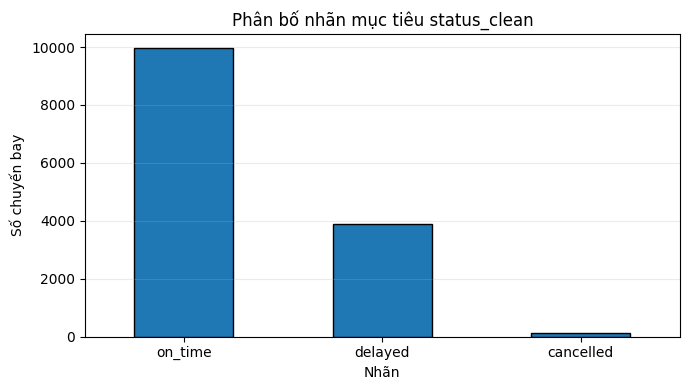

,Tỷ lệ (%)
status_clean,
on_time,71.32
delayed,27.83
cancelled,0.85


In [11]:
import matplotlib.pyplot as plt

if 'status_clean' in df.columns:
    counts = df['status_clean'].value_counts().reindex(['on_time','delayed','cancelled'], fill_value=0)
    ax=counts.plot(kind='bar', figsize=(7,4), edgecolor='black')
    ax.set_title('Phân bố nhãn mục tiêu status_clean')
    ax.set_xlabel('Nhãn'); ax.set_ylabel('Số chuyến bay'); ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=.25); plt.tight_layout(); plt.show()
    display((counts / counts.sum() * 100).round(2).rename('Tỷ lệ (%)').to_frame())

In [12]:
# Lưu dữ liệu sau xử lý xuống thư mục data/
data_dir = PROJECT_ROOT / 'data'
data_dir.mkdir(parents=True, exist_ok=True)

output_file = data_dir / 'flights_cleaned.csv'
df.to_csv(output_file, index=False)
print(f'Đã lưu thành công dữ liệu sau xử lý vào: {output_file} (Tổng số dòng: {len(df):,})')

Đã lưu thành công dữ liệu sau xử lý vào: d:\datamining_nhom8_updated\data\flights_cleaned.csv (Tổng số dòng: 13,965)


## 6. Kết luận và bàn giao cho TV3

- `delay_min`: số phút trễ; qua nửa đêm được hiệu chỉnh theo chu kỳ 24 giờ.
- `status_clean`: `on_time`, `delayed`, `cancelled`; ngưỡng mặc định là 15 phút.
- Chuyến hủy bắt buộc có `delay_min = NaN`.
- Chỉ bàn giao dữ liệu khi đủ 8 kiểm định đạt; nếu kiểm định không đạt, xử lý nguyên nhân thay vì bỏ qua cảnh báo.